Point Set Generation Network -
Vasile Miruna Maria
---
---



Descarcare date pix3d_dataset




In [ ]:
import os
import json
import numpy as np
from tensorflow import keras

In [ ]:
# Cell A1: dependențe
!pip install -q trimesh open3d PyMCubes scikit-image tqdm
# Torch: folosește versiunea recomandată de Colab (GPU)
import torch, torchvision
print("Torch:", torch.__version__, "CUDA:", torch.cuda.is_available())

Torch: 2.10.0+cu128 CUDA: True


In [ ]:
# Cell B1
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os
PROJECT_DIR = '/content/drive/MyDrive/3D_Reconstruction_Project'
RAW_DIR     = os.path.join(PROJECT_DIR, 'data', 'pix3d_raw')
PREP_DIR    = os.path.join(PROJECT_DIR, 'data', 'pix3d_preproc')
PC_DIR      = os.path.join(PREP_DIR, 'pointclouds')
OCC_DIR     = os.path.join(PREP_DIR, 'occupancy')


os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(PC_DIR, exist_ok=True)
os.makedirs(OCC_DIR, exist_ok=True)

print(" Memoria a revenit!")
print("RAW_DIR:", RAW_DIR)

Mounted at /content/drive
 Memoria a revenit!
RAW_DIR: /content/drive/MyDrive/3D_Reconstruction_Project/data/pix3d_raw


In [ ]:
%cd /content/drive/MyDrive/3D_Reconstruction_Project/data/pix3d_raw/


!rm -f pix3d.zip
!wget "http://pix3d.csail.mit.edu/data/pix3d.zip"


!rm -rf pix3d_temp_extract
!mkdir pix3d_temp_extract

!unzip -q pix3d.zip -d pix3d_temp_extract



if os.path.exists('pix3d_temp_extract/pix3d'):
    print("Moving contents from 'pix3d_temp_extract/pix3d'...")
    !mv pix3d_temp_extract/pix3d/* .
else:
    print("Moving contents directly from 'pix3d_temp_extract'...")
    !mv pix3d_temp_extract/* .

!rm -rf pix3d_temp_extract pix3d.zip

print(" Descărcarea și dezarhivarea s-au terminat cu succes!")

/content/drive/MyDrive/3D_Reconstruction_Project/data/pix3d_raw
--2026-05-08 18:08:32--  http://pix3d.csail.mit.edu/data/pix3d.zip
Resolving pix3d.csail.mit.edu (pix3d.csail.mit.edu)... 128.52.131.62
Connecting to pix3d.csail.mit.edu (pix3d.csail.mit.edu)|128.52.131.62|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3783261880 (3.5G) [application/zip]
Saving to: ‘pix3d.zip’

pix3d.zip           100%[===================>]   3.52G  13.7MB/s    in 4m 46s  

2026-05-08 18:13:19 (12.6 MB/s) - ‘pix3d.zip’ saved [3783261880/3783261880]

Moving contents directly from 'pix3d_temp_extract'...
 Descărcarea și dezarhivarea s-au terminat cu succes!


In [ ]:
import os

print(f"Verific conținutul directorului RAW_DIR: {RAW_DIR}")
for root, dirs, files in os.walk(RAW_DIR):
    if root == RAW_DIR:
        print("\nFișiere și directoare găsite:")
        for d in dirs:
            print(f"📁 {d}")
        for f in files:
            print(f"📄 {f}")
        break

Verific conținutul directorului RAW_DIR: /content/drive/MyDrive/3D_Reconstruction_Project/data/pix3d_raw

Fișiere și directoare găsite:
📁 img
📁 mask
📁 model
📄 pix3d.json


Extragere

In [ ]:
import os
import json
from tqdm import tqdm
import trimesh
import numpy as np

RAW_DIR = '/content/drive/MyDrive/3D_Reconstruction_Project/data/pix3d_raw'

PC_DIR = '/content/drive/MyDrive/3D_Reconstruction_Project/data/pix3d_preproc/pointclouds'
os.makedirs(PC_DIR, exist_ok=True)

ann_path = os.path.join(RAW_DIR, 'pix3d.json')
print(f"Citesc adnotările din: {ann_path}")

with open(ann_path, 'r') as f:
    annotations = json.load(f)

MAX_SAMPLES = 200
modele_salvate = 0

print("Încep procesarea (extragerea punctelor 3D)...")

for i, item in enumerate(tqdm(annotations[:MAX_SAMPLES])):
    img_rel = item.get('img')
    model_rel = item.get('model')

    if model_rel is None:
        continue

    model_path = os.path.join(RAW_DIR, model_rel)
    if not os.path.exists(model_path):
        continue

    try:
        mesh = trimesh.load(model_path, force='mesh')
        if mesh.is_empty:
            continue

        # Extragem cele 2048 de puncte
        pc = mesh.sample(2048).astype(np.float32)

        pc_fname = os.path.join(PC_DIR, f'pc_{i:05d}.npy')
        np.save(pc_fname, pc)
        modele_salvate += 1

    except Exception as e:
        pass

print(f"\nS-au extras și salvat {modele_salvate} modele 3D în Drive.")

Citesc adnotările din: /content/drive/MyDrive/3D_Reconstruction_Project/data/pix3d_raw/pix3d.json
Încep procesarea (extragerea punctelor 3D)...


100%|██████████| 200/200 [00:10<00:00, 18.32it/s]


S-au extras și salvat 200 modele 3D în Drive.


Algoritm PSGN

In [ ]:
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader, random_split
import cv2
import numpy as np
import os
import json

# --- 1. CONDUCTA DE DATE  ---
class Pix3D_PSGN_Dataset(Dataset):
    def __init__(self, raw_dir, pc_dir, ann_path, max_samples=200):
        with open(ann_path, 'r') as f:
            annotations = json.load(f)

        self.data = []
        for i, item in enumerate(annotations[:max_samples]):
            pc_fname = os.path.join(pc_dir, f'pc_{i:05d}.npy')
            img_path = os.path.join(raw_dir, item.get('img', ''))

            # Verificăm să existe și poza 2D și norul de puncte 3D
            if os.path.exists(pc_fname) and os.path.exists(img_path):
                self.data.append({'img_path': img_path, 'pc_path': pc_fname})

        self.transform = transforms.Compose([
            transforms.ToPILImage(),
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]

        # Citim Poza 2D
        img = cv2.imread(item['img_path'])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_tensor = self.transform(img)

        # Citim Punctele 3D
        pc = np.load(item['pc_path']).astype(np.float32)
        # centrare
        pc = pc - np.mean(pc, axis=0)
        pc = pc / np.max(np.linalg.norm(pc, axis=1))
        pc_tensor = torch.from_numpy(pc)

        return {'imagine': img_tensor, 'puncte': pc_tensor}


# --- 2. PSGN ---
class PSGN(nn.Module):
    def __init__(self, num_points=2048):
        super(PSGN, self).__init__()
        self.num_points = num_points

        # Encoder (ResNet)
        resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        self.encoder = nn.Sequential(*list(resnet.children())[:-1])

        # Decoder (Multi Linear Perception)
        self.decoder = nn.Sequential(
            nn.Linear(512, 1024),
            nn.ReLU(),
            nn.Linear(1024, 2048),
            nn.ReLU(),
            nn.Linear(2048, num_points * 3),
            nn.Tanh()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = x.view(x.size(0), -1)
        puncte = self.decoder(x)
        puncte = puncte.view(-1, self.num_points, 3)
        return puncte

# --- 3. FUNCȚIA DE EROARE  ---
def chamfer_distance(p1, p2):
    dist = torch.cdist(p1, p2)
    min_dist_p1 = torch.min(dist, dim=2)[0]
    min_dist_p2 = torch.min(dist, dim=1)[0]
    return torch.mean(min_dist_p1) + torch.mean(min_dist_p2)

# --- 4. PREGĂTIREA ȘI ÎMPĂRȚIREA DATELOR (TRAIN / TEST) ---
RAW_DIR = '/content/drive/MyDrive/3D_Reconstruction_Project/data/pix3d_raw'
PC_DIR = '/content/drive/MyDrive/3D_Reconstruction_Project/data/pix3d_preproc/pointclouds'
ANN_PATH = os.path.join(RAW_DIR, 'pix3d.json')

dataset_complet = Pix3D_PSGN_Dataset(RAW_DIR, PC_DIR, ANN_PATH)

total_imagini = len(dataset_complet)
train_size = int(0.8 * total_imagini)
test_size = total_imagini - train_size

print(f" Dataset total: {total_imagini} perechi valide.")
print(f" Împart datele: {train_size} pentru Antrenament, {test_size} pentru Testare.")

train_dataset, test_dataset = random_split(dataset_complet, [train_size, test_size])

dataloader_train = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=2)
dataloader_test = DataLoader(test_dataset, batch_size=8, shuffle=False, num_workers=2)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = PSGN(num_points=2048).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

print(f"\n Încep antrenamentul pe {device}...\n")

# --- 5. START ANTRENAMENT ---
epoci = 50

for epoca in range(epoci):
    model.train()
    loss_total = 0.0

    for batch in dataloader_train:
        imagini = batch['imagine'].to(device)
        puncte_reale = batch['puncte'].to(device)

        optimizer.zero_grad()
        puncte_prezise = model(imagini)

        loss = chamfer_distance(puncte_prezise, puncte_reale)
        loss.backward()

        optimizer.step()

        loss_total += loss.item()

    loss_mediu = loss_total / len(dataloader_train)
    print(f" Epoca [{epoca+1:02d}/{epoci}] -> Eroare (Chamfer Loss): {loss_mediu:.4f}")

# --- 6. SALVAREA MODELULUI ---
torch.save(model.state_dict(), '/content/drive/MyDrive/3D_Reconstruction_Project/psgn_model.pth')
print("\n Antrenamentul s-a terminat! Modelul a fost salvat cu succes în Drive.")

 Dataset total: 200 perechi valide.
 Împart datele: 160 pentru Antrenament, 40 pentru Testare.
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 218MB/s]



 Încep antrenamentul pe cuda...

 Epoca [01/50] -> Eroare (Chamfer Loss): 0.1629
 Epoca [02/50] -> Eroare (Chamfer Loss): 0.1207
 Epoca [03/50] -> Eroare (Chamfer Loss): 0.1096
 Epoca [04/50] -> Eroare (Chamfer Loss): 0.1004
 Epoca [05/50] -> Eroare (Chamfer Loss): 0.0938
 Epoca [06/50] -> Eroare (Chamfer Loss): 0.0900
 Epoca [07/50] -> Eroare (Chamfer Loss): 0.0831
 Epoca [08/50] -> Eroare (Chamfer Loss): 0.0812
 Epoca [09/50] -> Eroare (Chamfer Loss): 0.0783
 Epoca [10/50] -> Eroare (Chamfer Loss): 0.0805
 Epoca [11/50] -> Eroare (Chamfer Loss): 0.0767
 Epoca [12/50] -> Eroare (Chamfer Loss): 0.0735
 Epoca [13/50] -> Eroare (Chamfer Loss): 0.0720
 Epoca [14/50] -> Eroare (Chamfer Loss): 0.0722
 Epoca [15/50] -> Eroare (Chamfer Loss): 0.0697
 Epoca [16/50] -> Eroare (Chamfer Loss): 0.0664
 Epoca [17/50] -> Eroare (Chamfer Loss): 0.0673
 Epoca [18/50] -> Eroare (Chamfer Loss): 0.0712
 Epoca [19/50] -> Eroare (Chamfer Loss): 0.0725
 Epoca [20/50] -> Eroare (Chamfer Loss): 0.0708
 Epoca

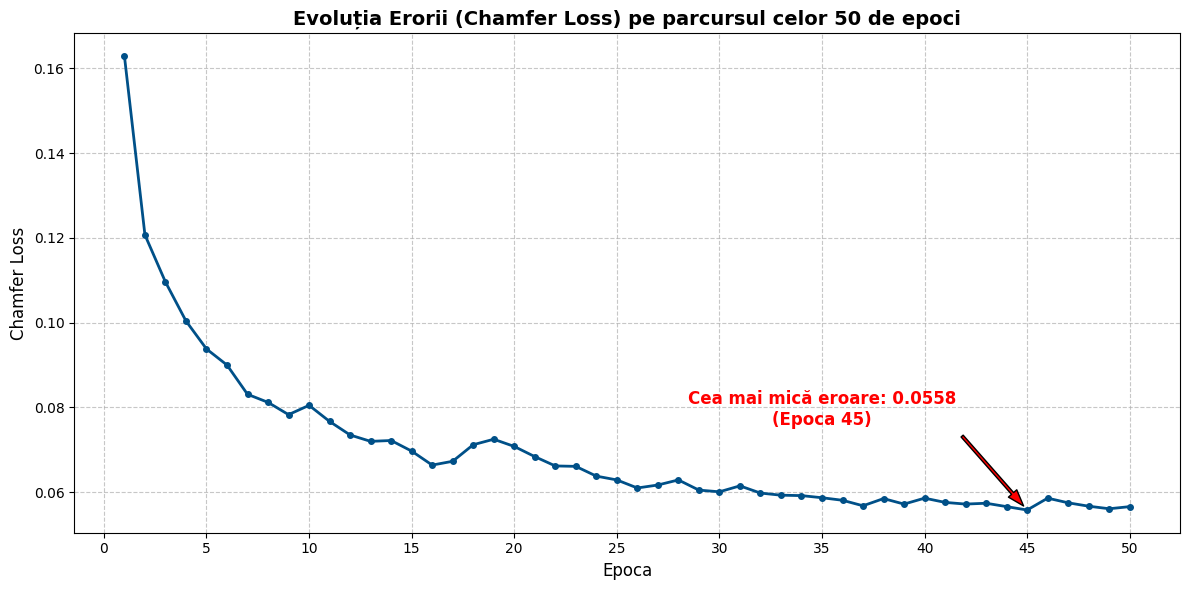

In [ ]:
import matplotlib.pyplot as plt

epoci = list(range(1, 51))
chamfer_loss = [
    0.1629, 0.1207, 0.1096, 0.1004, 0.0938, 0.0900, 0.0831, 0.0812, 0.0783, 0.0805,
    0.0767, 0.0735, 0.0720, 0.0722, 0.0697, 0.0664, 0.0673, 0.0712, 0.0725, 0.0708,
    0.0684, 0.0662, 0.0661, 0.0638, 0.0629, 0.0610, 0.0617, 0.0629, 0.0605, 0.0601,
    0.0615, 0.0598, 0.0593, 0.0592, 0.0587, 0.0581, 0.0568, 0.0585, 0.0572, 0.0586,
    0.0576, 0.0572, 0.0574, 0.0566, 0.0558, 0.0586, 0.0575, 0.0567, 0.0561, 0.0566
]

plt.figure(figsize=(12, 6))
plt.plot(epoci, chamfer_loss, color='#005088', linewidth=2, marker='.', markersize=8)

plt.title('Evoluția Erorii (Chamfer Loss) pe parcursul celor 50 de epoci', fontsize=14, fontweight='bold')
plt.xlabel('Epoca', fontsize=12)
plt.ylabel('Chamfer Loss', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(range(0, 51, 5))

min_loss = min(chamfer_loss)
min_epoca = chamfer_loss.index(min_loss) + 1

plt.annotate(f'Cea mai mică eroare: {min_loss}\n(Epoca {min_epoca})',
             xy=(min_epoca, min_loss),
             xytext=(min_epoca - 10, min_loss + 0.02),
             arrowprops=dict(facecolor='red', shrink=0.05, width=2, headwidth=8),
             fontsize=12, color='red', fontweight='bold', ha='center')

plt.tight_layout()
plt.show()

/tmp/ipykernel_18588/3660971137.py:37: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


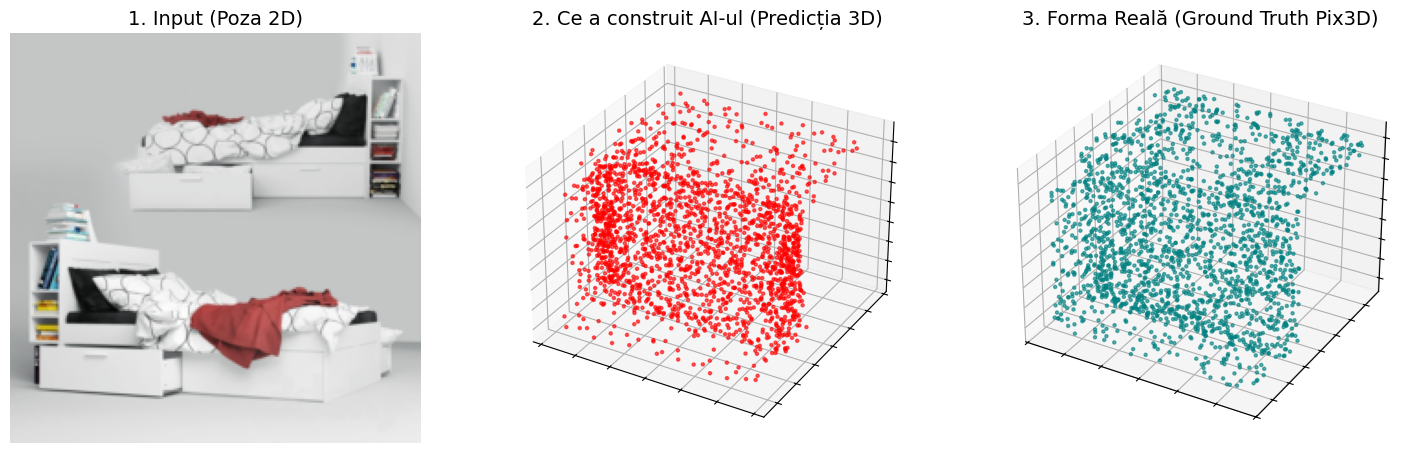

In [ ]:
import matplotlib.pyplot as plt

model.eval()

pachet_test = next(iter(dataloader_test))

imagine_2d = pachet_test['imagine'][0].unsqueeze(0).to(device)
ground_truth_3d = pachet_test['puncte'][0].numpy()

with torch.no_grad():
    predictie_3d = model(imagine_2d)[0].cpu().numpy()

# --- PREGĂTIM AFIȘAREA ---
fig = plt.figure(figsize=(18, 6))

# Fereastra 1: Poza 2D (Input-ul)
ax1 = fig.add_subplot(131)
img_afisaj = pachet_test['imagine'][0].permute(1, 2, 0).numpy()

img_afisaj = np.clip((img_afisaj * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]), 0, 1)
ax1.imshow(img_afisaj)
ax1.set_title("1. Input (Poza 2D)", fontsize=14)
ax1.axis('off')

# Fereastra 2: Predicția AI-ului (Punctele create de el)
ax2 = fig.add_subplot(132, projection='3d')
ax2.scatter(predictie_3d[:, 0], predictie_3d[:, 1], predictie_3d[:, 2], c='red', s=5, alpha=0.6)
ax2.set_title("2. Ce a construit AI-ul (Predicția 3D)", fontsize=14)
ax2.set_xticklabels([]); ax2.set_yticklabels([]); ax2.set_zticklabels([])

# Fereastra 3: Realitatea (Ground Truth)
ax3 = fig.add_subplot(133, projection='3d')
ax3.scatter(ground_truth_3d[:, 0], ground_truth_3d[:, 1], ground_truth_3d[:, 2], c='teal', s=5, alpha=0.6)
ax3.set_title("3. Forma Reală (Ground Truth Pix3D)", fontsize=14)
ax3.set_xticklabels([]); ax3.set_yticklabels([]); ax3.set_zticklabels([])

plt.tight_layout()
plt.show()